# Равновесный $\delta$ в COSY Infinity

Та же лестница, что в расчёте на кольце Bell. Решётка `magnetic_2`, секступоли выключены, полость этого кольца (гармоника 5, 0.2 МВ).

| | Julia | COSY |
|---|---|---|
| M1 формула | $\eta,\xi\to\delta_\mathrm{eq}$ | карта `OV 3 3 0` и `OV 3 2 1`, то же |
| M2 нормальная форма | произведение Ли, Dragt–Finn | `DANF` / `TS` той же 6D-карты с полостью |
| M3 усечённая карта | полином степени 3 | `TR` с `TY=-21` (без производящей функции) |
| M4 симплектизация | точный интегратор | `TR` с `TY=0` (производящая функция COSY) |

Число $\delta_\mathrm{eq}$ считается из карты. Трекинг показывает, что центр симметричного колебания на него садится, и насколько его сдвигает бетатронное удлинение.

## Что именно считает COSY

В COSY нет «точного интегратора уравнений движения», как в Julia. Есть **однооборотная карта** — полином, которым дифференциальная алгебра заменяет все элементы кольца за один оборот. Дальше четыре разных обращения с этой картой.

**M1. Формула.** Полость выключена. `OV 3 3 0` строит карту, из неё читаются коэффициенты $\eta_0,\eta_1$ и удлинение $\Lambda/J$ (среднее квадратичной части пути по эллипсу). `OV 3 2 1` + `TP` даёт хроматичность $\xi$. Частицы нет: только алгебра. Из $\tau=\eta_0\delta+\eta_1\delta^2+\Lambda=0$ следует $\delta_\mathrm{eq}=-(\eta_1\delta_m^2/2+\Lambda)/\eta_0$.

**M2. Нормальная форма.** Полость включена, карта уже 6D. `DANF` переписывает её в нормальную форму (вращение по трём действиям). `TS` читает тюны этой формы, в том числе $Q_s$. Это COSY-аналог произведения Ли в Julia. Частицы снова нет: карта меняет вид, не гоняется точка.

**M3. Трекинг карты.** Штатный трекер COSY: `TR N 1 1 6 … -21 0 -12`. Аргумент `TY=-21` выключает производящую функцию: каждый оборот есть `POLVAL` того же полинома степени 3. Это не шаг по магниту, а итерация усечённой карты. Частицы задаются `SR`, вывод — `TRPRAY`.

**M4. Симплектический `TR`.** Тот же `TR`, но `TY=0`: COSY строит производящую функцию карты и на каждом обороте поправляет точку (fixed-point). В этом репозитории так гоняют `TRACK` в `utilities.fox` и все `track_magnetic_2_*.fox`. `TY=-21` выключает поправку (комментарий там же: для NICA_FULL). Это не поэлементный интегратор по $s$: решётка уже свёрнута в однооборотную карту, `TR` крутит эту карту.

In [1]:
%matplotlib inline
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display

DAT = Path("../dat/magnetic_2")
if not (DAT / "delta_eq_map.dat").is_file():
    DAT = Path(r"C:/GIT_REPOS/SCT_2/COSY/dat/magnetic_2")

plt.rcParams.update({"figure.dpi": 120, "axes.grid": True, "font.size": 11})

def load_kv(path):
    out = {}
    for line in Path(path).read_text().splitlines()[1:]:
        k, v = line.split()
        out[k] = float(v)
    return out

def load_curve(path):
    return np.loadtxt(path, skiprows=1, unpack=True)

M = load_kv(DAT / "delta_eq_map.dat")
NF = load_kv(DAT / "delta_eq_nf.dat")
s_x, bx, _ = load_curve(DAT / "BETAX")
s_y, by, _ = load_curve(DAT / "BETAY")
s_d, dx, _ = load_curve(DAT / "DISPX")
def load_trpray(path):
    t = np.loadtxt(path, comments="#")
    t = t[t[:, 1] >= 2]
    t[:, 1] -= 1
    return t

turns = load_trpray(DAT / "delta_eq_turns.dat")
symp = load_trpray(DAT / "delta_eq_turns_symp.dat")
gamma = M["gamma"]
KG = (gamma + 1.0) / gamma
C = M["Cs"]
print("C = %.6f m   eta0 = %.6f   eta1 = %.6f" % (C, M["eta0"], M["eta1"]))
print("xi = (%.4f, %.4f)   Qs_nf = %.6f" % (M["xi_x"], M["xi_y"], NF["Qs_nf"]))

C = 117.388296 m   eta0 = -0.533848   eta1 = 1.017794
xi = (-1.8408, -1.8477)   Qs_nf = 0.012961


## 0. Твисс без полости

Периодические $\beta_x$, $\beta_y$ и $D_x$. Секступоли и полость выключены. Два арка, прямая посередине, функции замыкаются.

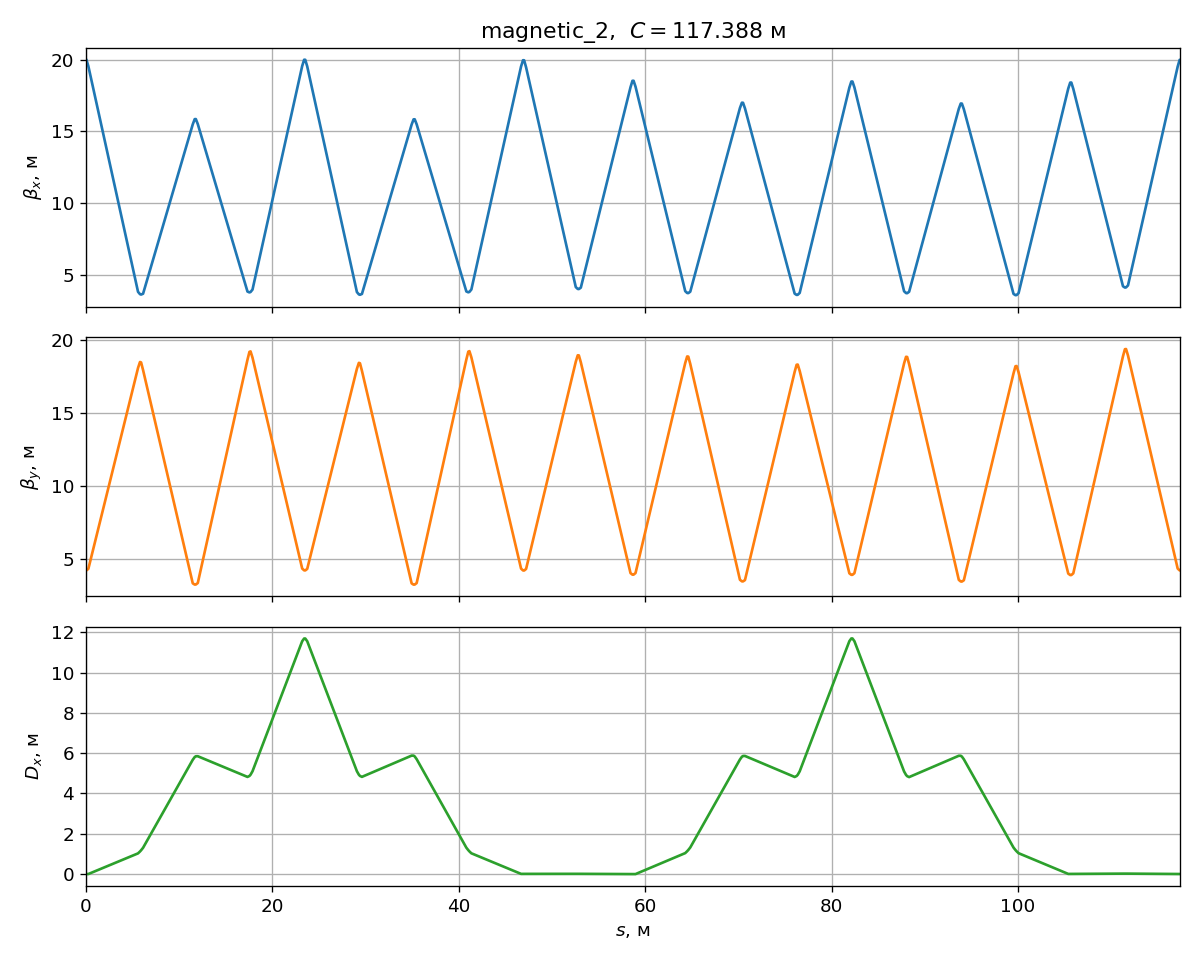

In [2]:
fig, ax = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
ax[0].plot(s_x, bx, lw=1.6, color="C0")
ax[0].set_ylabel(r"$\beta_x$, м")
ax[1].plot(s_y, by, lw=1.6, color="C1")
ax[1].set_ylabel(r"$\beta_y$, м")
ax[2].plot(s_d, dx, lw=1.6, color="C2")
ax[2].set_ylabel(r"$D_x$, м")
ax[2].set_xlabel(r"$s$, м")
ax[0].set_title(r"magnetic_2,  $C=%.3f$ м" % s_x[-1])
for a in ax:
    a.set_xlim(0, s_x[-1])
fig.tight_layout()
fig.savefig(DAT / "fig_twiss.png")
display(Image(filename=str(DAT / "fig_twiss.png")))
plt.close()

## M1. Формула с карты

`OV 3 3 0` даёт $\eta_0,\eta_1$ и удлинение $\Lambda/J$ средним квадратичной части пути по эллипсу. `OV 3 2 1` + `TP` даёт хроматичность. Запаздывание за оборот

$$
\tau=\eta_0\delta+\eta_1\delta^2+\Lambda,\qquad
\Lambda=(\Lambda/J)\,J,
\qquad
\frac{\Lambda}{J}=-\frac{2\pi\xi}{C}\quad\text{если брать }\xi.
$$

Среднее запаздывание за период равно нулю, поэтому

$$
\delta_\mathrm{eq}=-\frac{\eta_1\delta_m^2/2+\Lambda}{\eta_0}.
$$

Без поперечной амплитуды $\Lambda=0$. Два способа взять $\Lambda$: с эллипса карты пути и из $\xi$.

In [3]:
print("eta0, eta1     % .6f  % .6f" % (M["eta0"], M["eta1"]))
print("Lambda/J  карта пути   x %.6e  y %.6e" % (M["LT_Jx"], M["LT_Jy"]))
print("Lambda/J  из xi (TP)   x %.6e  y %.6e" % (M["LT_xi_x"], M["LT_xi_y"]))
print("deq0 (без бетатрона)           %.6e" % M["deq0"])
print("deq  10 мм x  (путь / xi)      %.6e / %.6e" % (M["deq_x"], M["deq_x_xi"]))
print("deq  10 мм y  (путь / xi)      %.6e / %.6e" % (M["deq_y"], M["deq_y_xi"]))
print("сдвиг -Lambda/eta0   x %.6e  y %.6e" % (
    M["deq_x"] - M["deq0"], M["deq_y"] - M["deq0"]))

eta0, eta1     -0.533848   1.017794
Lambda/J  карта пути   x 7.882092e-02  y 1.193759e-01
Lambda/J  из xi (TP)   x 9.852849e-02  y 9.889664e-02
deq0 (без бетатрона)           9.532610e-07
deq  10 мм x  (путь / xi)      1.352468e-06 / 1.452281e-06
deq  10 мм y  (путь / xi)      3.789369e-06 / 3.302828e-06
сдвиг -Lambda/eta0   x 3.992069e-07  y 2.836108e-06


## Коэффициенты разложения: COSY DA против Julia

COSY строит однооборотный полином `MAP`. Ниже сравниваются **коэффициенты** (и их инвариантные свёртки), не трекинг. Julia --- произведение Ли того же `magnetic_2`, числа из `v08_summary.txt`. В COSY они не подставлялись.

Две разные хроматичности в COSY: `TP` (энергия --- параметр, `OV 3 2 1`) и $\xi$ из квадратичной части пути `MAP(5)` на эллипсе (`OV 3 3 0`). С Julia сходится вторая.

                                                COSY DA      Julia Lie         отн.


                                    C, м        117.388        117.388   -8.47e-16
                                   eta_0      -0.533848       -0.53376    1.65e-04
                                   eta_1        1.01779        1.01676    1.02e-03
                        Q_s (DANF / Lie)      0.0129613        0.01296    1.04e-04
                            Q_x линейный       0.459924       0.462452   -5.47e-03
                            Q_y линейный       0.457408       0.462016   -9.97e-03
               xi_x из MAP(5) на эллипсе       -1.47261        -1.4624    6.98e-03
               xi_y из MAP(5) на эллипсе       -2.23029        -2.2267    1.61e-03
                       xi_x процедура TP        -1.8408        -1.4624    2.59e-01
                       xi_y процедура TP       -1.84768        -2.2267   -1.70e-01
                 ddelta_eq/d J_x из пути       0.147647       0.146653    6.78e-03
                 ddelta_eq/d J_y из пути       0.223614        0.22329    1.45e-03
   

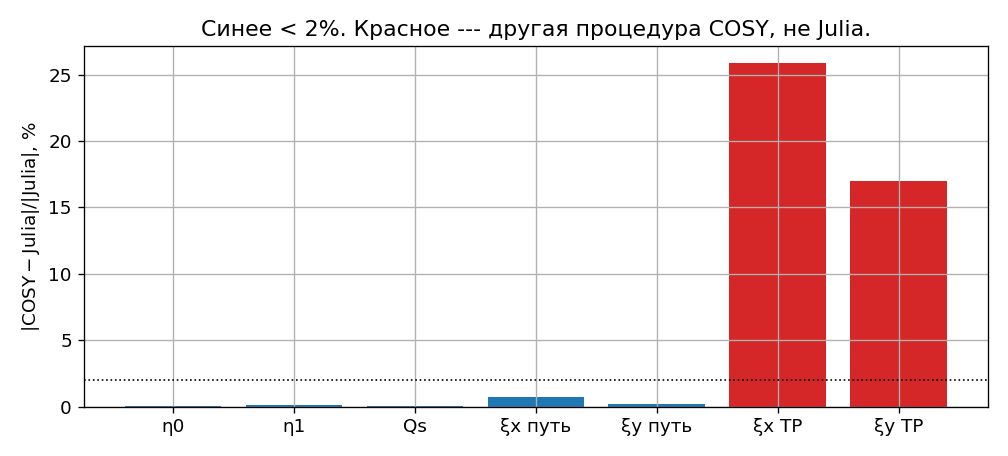

In [4]:
J = dict(
    C=117.388296, eta0=-0.533760, eta1=1.016756,
    Qs=0.012960, Qx=0.462452, Qy=0.462016,
    xix=-1.4624, xiy=-2.2267,
    dx=0.146653, dy=0.223290,
)
C = M["Cs"]
xi_path_x = -M["LT_Jx"] * C / (2 * np.pi)
xi_path_y = -M["LT_Jy"] * C / (2 * np.pi)
dx_path = -M["LT_Jx"] / M["eta0"]
dy_path = -M["LT_Jy"] / M["eta0"]
rows = [
    (r"$C$, м", M["Cs"], J["C"]),
    (r"$\eta_0$", M["eta0"], J["eta0"]),
    (r"$\eta_1$", M["eta1"], J["eta1"]),
    (r"$Q_s$ (DANF / Lie)", NF["Qs_nf"], J["Qs"]),
    (r"$Q_x$ линейный", M["Qx"], J["Qx"]),
    (r"$Q_y$ линейный", M["Qy"], J["Qy"]),
    (r"$\xi_x$ из MAP(5) на эллипсе", xi_path_x, J["xix"]),
    (r"$\xi_y$ из MAP(5) на эллипсе", xi_path_y, J["xiy"]),
    (r"$\xi_x$ процедура TP", M["xi_x"], J["xix"]),
    (r"$\xi_y$ процедура TP", M["xi_y"], J["xiy"]),
    (r"$\partial\delta_\mathrm{eq}/\partial J_x$ из пути", dx_path, J["dx"]),
    (r"$\partial\delta_\mathrm{eq}/\partial J_y$ из пути", dy_path, J["dy"]),
    (r"$\partial\delta_\mathrm{eq}/\partial J_x$ из TP", M["d_deq_dJx"], J["dx"]),
    (r"$\partial\delta_\mathrm{eq}/\partial J_y$ из TP", M["d_deq_dJy"], J["dy"]),
]
print("%40s %14s %14s %12s" % ("", "COSY DA", "Julia Lie", "отн."))
for name, c, j in rows:
    rel = (c - j) / j if j != 0 else np.nan
    print("%40s %14.6g %14.6g %11.2e" % (name.replace("$", "").replace("\\mathrm{eq}", "eq").replace("\\partial", "d").replace("\\", ""), c, j, rel))

print()
print("сырые мономы MAP(5), COSY, без Julia-аналога в тех же координатах:")
for k in ("MAP5_d", "MAP5_dd", "MAP5_xx", "MAP5_xa", "MAP5_aa", "MAP5_yy", "MAP5_yb", "MAP5_bb"):
    if k in M:
        print("  %-10s % .8e" % (k, M[k]))

labels = ["η0", "η1", "Qs", "ξx путь", "ξy путь", "ξx TP", "ξy TP"]
cosy_v = [M["eta0"], M["eta1"], NF["Qs_nf"], xi_path_x, xi_path_y, M["xi_x"], M["xi_y"]]
jul_v = [J["eta0"], J["eta1"], J["Qs"], J["xix"], J["xiy"], J["xix"], J["xiy"]]
rel = np.array([(c - j) / j for c, j in zip(cosy_v, jul_v)])
fig, ax = plt.subplots(figsize=(8.4, 3.8))
colors = ["C0" if abs(r) < 0.02 else "C3" for r in rel]
ax.bar(np.arange(len(labels)), np.abs(rel) * 100, color=colors)
ax.axhline(2.0, color="k", ls=":", lw=1)
ax.set_xticks(np.arange(len(labels)), labels)
ax.set_ylabel(r"$|\mathrm{COSY}-\mathrm{Julia}|/|\mathrm{Julia}|$, %")
ax.set_title("Синее < 2%. Красное --- другая процедура COSY, не Julia.")
fig.tight_layout()
fig.savefig(DAT / "fig_coeff.png")
display(Image(filename=str(DAT / "fig_coeff.png")))
plt.close()

## M2. Нормальная форма DA

После полости карта 6D. `DANF` раскладывает её в нормальную форму (COSY-аналог произведения Ли). `TS` читает тюны, в том числе синхротронный, как DA по амплитудам. Начало нормальной формы — неподвижная точка: все `CONS(MA)=0`, то есть при нулевых действиях сдвиг энергии нуль, как и должно быть.

In [5]:
print("Qs из DANF/TS = %.6f   (период %.2f оборота)" % (NF["Qs_nf"], 1 / NF["Qs_nf"]))
print("Qx, Qy из NF  = %.6f, %.6f" % (NF["Qx_nf"], NF["Qy_nf"]))
print("Qx, Qy линейные карты без полости = %.6f, %.6f" % (M["Qx"], M["Qy"]))
print("неподвижная точка MA =",
      [NF[k] for k in ("MA1", "MA2", "MA3", "MA4", "MA5", "MA6")])

Qs из DANF/TS = 0.012961   (период 77.15 оборота)
Qx, Qy из NF  = 0.446284, 0.476682
Qx, Qy линейные карты без полости = 0.459924, 0.457408
неподвижная точка MA = [0.0, 0.0, 0.0, 0.0, 0.0, 0.0]


In [6]:
def ray(tab, rid):
    d = tab[tab[:, 1] == rid]
    n, x, a, y, b, t, D = (d[:, k] for k in (0, 2, 3, 4, 5, 6, 7))
    delta = D * gamma / (gamma + 1.0)
    return dict(n=n, x=x, a=a, y=y, b=b, t=t, D=D, delta=delta)


def runmean(v):
    v = np.asarray(v, dtype=float)
    return np.cumsum(v) / np.arange(1, len(v) + 1)

def synchrotron_tune(delta):
    x = delta - delta.mean()
    spec = np.abs(np.fft.rfft(x))
    freq = np.fft.rfftfreq(len(x))
    return float(freq[1 + np.argmax(spec[1:])])

def harmonic_center(delta, Qs, drop=0):
    n = np.arange(len(delta), dtype=float)[drop:]
    y = np.asarray(delta, dtype=float)[drop:]
    w = 2.0 * np.pi * Qs
    A = np.column_stack([
        np.ones_like(n), np.cos(w * n), np.sin(w * n),
        np.cos(2 * w * n), np.sin(2 * w * n),
    ])
    coef, *_ = np.linalg.lstsq(A, y, rcond=None)
    rss = float(np.sum((y - A @ coef) ** 2))
    return float(coef[0]), coef, rss

def refine_tune(delta, Q0, drop=0, span=4e-4, ngrid=161):
    best = (np.inf, Q0, 0.0)
    for Q in np.linspace(Q0 - span, Q0 + span, ngrid):
        c, _, rss = harmonic_center(delta, Q, drop)
        if rss < best[0]:
            best = (rss, Q, c)
    return best[1], best[2]

R = {k: ray(turns, k) for k in range(1, 6)}
S = {k: ray(symp, k) for k in (1, 2)}
Qs0 = synchrotron_tune(R[1]["delta"])
drop = int(5.0 / Qs0)
Qs, c1 = refine_tune(R[1]["delta"], Qs0, drop=drop)
c2, _, _ = harmonic_center(R[2]["delta"], Qs, drop=drop)
c3, _, _ = harmonic_center(R[3]["delta"], Qs, drop=drop)
c4, _, _ = harmonic_center(R[4]["delta"], Qs, drop=drop)
c5, _, _ = harmonic_center(R[5]["delta"], Qs, drop=drop)
print("Qs трекинг = %.6f   Qs DANF = %.6f" % (Qs, NF["Qs_nf"]))

Qs трекинг = 0.012927   Qs DANF = 0.012961


## 01. Ряд $\delta$ при включённом ВЧ, без бетатрона

Центр глазом не виден: он в тысячу раз меньше размаха. Горизонталь — число с карты, не подгонка.

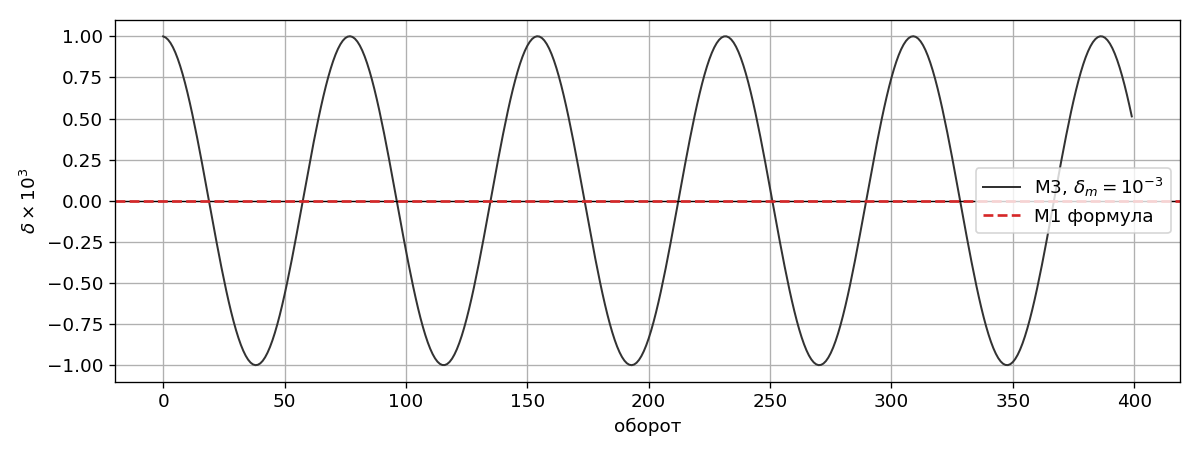

размах 1.000e-03,  формула 9.533e-07


In [7]:
nshow = 400
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(R[1]["n"][:nshow], R[1]["delta"][:nshow] * 1e3, lw=1.2, color="0.2",
        label=r"M3, $\delta_m=10^{-3}$")
ax.axhline(0.0, color="k", lw=0.8)
ax.axhline(M["deq0"] * 1e3, color="C3", ls="--", lw=1.6, label="M1 формула")
ax.set_xlabel("оборот")
ax.set_ylabel(r"$\delta\times 10^{3}$")
ax.legend()
fig.tight_layout()
fig.savefig(DAT / "fig_01_delta.png")
display(Image(filename=str(DAT / "fig_01_delta.png")))
plt.close()
print("размах %.3e,  формула %.3e" % (
    0.5 * (R[1]["delta"].max() - R[1]["delta"].min()), M["deq0"]))

## 02. Центр колебания

Постоянный член гармонической подгонки после уточнения $Q_s$ — это уровень, вокруг которого качается частица. Не сумма всех отсчётов.

                 центр M3       M1 карта        разница
  без beta   1.144535e-06   9.532610e-07   1.912744e-07
   10 мм x   1.625949e-06   1.352468e-06   2.734813e-07
   10 мм y   3.453358e-06   3.789369e-06  -3.360110e-07
M4 (SY) без beta 1.143714e-06   10 мм x 1.626454e-06


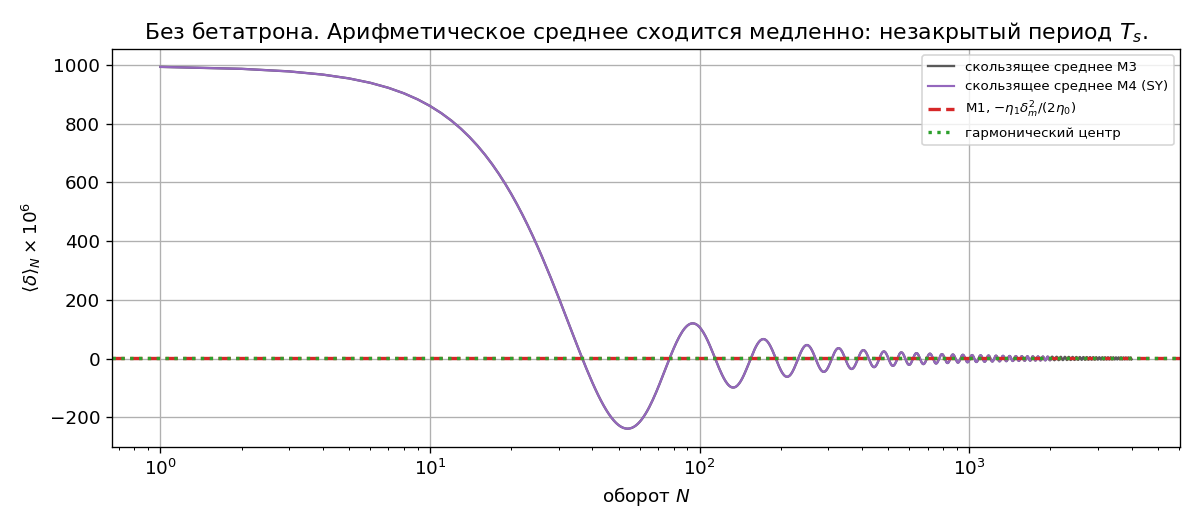

In [8]:
print("%10s %14s %14s %14s" % ("", "центр M3", "M1 карта", "разница"))
for name, c, key in [
    ("без beta", c1, "deq0"),
    ("10 мм x", c2, "deq_x"),
    ("10 мм y", c3, "deq_y"),
]:
    print("%10s %14.6e %14.6e %14.6e" % (name, c, M[key], c - M[key]))

cs1, _, _ = harmonic_center(S[1]["delta"], Qs, drop=min(drop, len(S[1]["delta"]) // 5))
cs2, _, _ = harmonic_center(S[2]["delta"], Qs, drop=min(drop, len(S[2]["delta"]) // 5))
print("M4 (SY) без beta %.6e   10 мм x %.6e" % (cs1, cs2))

fig, ax = plt.subplots(figsize=(10, 4.4))
ax.set_xscale("log")
rm1 = runmean(R[1]["delta"][1:])
ax.plot(R[1]["n"][1:], rm1 * 1e6, lw=1.4, color="0.35", label="скользящее среднее M3")
ax.plot(S[1]["n"][1:], runmean(S[1]["delta"][1:]) * 1e6, lw=1.3, color="C4",
        label="скользящее среднее M4 (SY)")
ax.axhline(M["deq0"] * 1e6, color="C3", ls="--", lw=2, label=r"M1, $-\eta_1\delta_m^2/(2\eta_0)$")
ax.axhline(c1 * 1e6, color="C2", ls=":", lw=2, label="гармонический центр")
ax.set_xlabel("оборот $N$")
ax.set_ylabel(r"$\langle\delta\rangle_N\times 10^{6}$")
ax.set_title("Без бетатрона. Арифметическое среднее сходится медленно: незакрытый период $T_s$.")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(DAT / "fig_02_runmean.png")
display(Image(filename=str(DAT / "fig_02_runmean.png")))
plt.close()

## 04. Бетатронный эллипс при включённом ВЧ

Частица с $A_x=10$ мм ходит по эллипсу $(x,a)$. Полоса дышит из-за синхротрона через дисперсию.

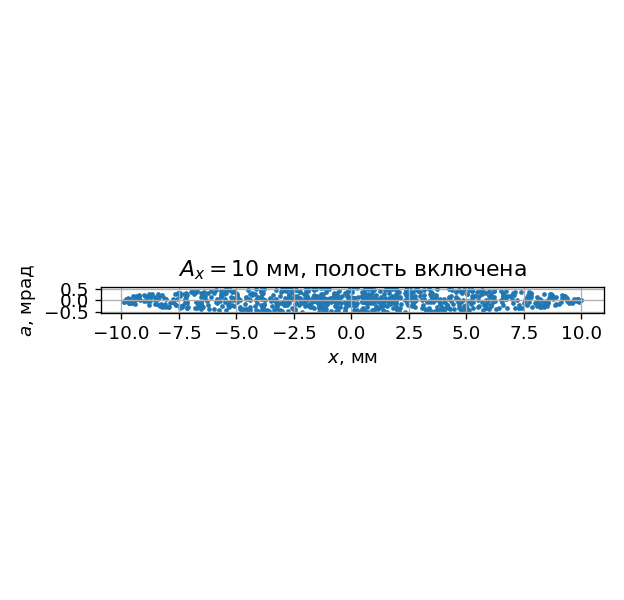

In [9]:
fig, ax = plt.subplots(figsize=(5.2, 5.0))
ax.scatter(R[2]["x"][:800] * 1e3, R[2]["a"][:800] * 1e3, s=8, lw=0, color="C0")
ax.set_xlabel(r"$x$, мм")
ax.set_ylabel(r"$a$, мрад")
ax.set_title(r"$A_x=10$ мм, полость включена")
ax.set_aspect("equal", adjustable="box")
fig.tight_layout()
fig.savefig(DAT / "fig_04_ellipse.png")
display(Image(filename=str(DAT / "fig_04_ellipse.png")))
plt.close()

## 05. Зачем бетатрон сдвигает $\delta_\mathrm{eq}$

Частица с амплитудой $A$ не едет по оси, а ходит по эллипсу. В магните этот эллипс чуть длиннее опорной орбиты. За оборот лишняя длина есть $\Lambda\cdot C$. Полость видит только опоздание, поэтому лишний путь неотличим от другого импульса. Чтобы среднее опоздание за синхротронный период осталось нулём, центр $\delta$ сдвигается на $-\Lambda/\eta_0$.

Теория (симплектическое тождество): $\Lambda=-(2\pi/C)J\xi$. Это не подгонка, а та же хроматичность, которую COSY считает через `TP`.

Старый график за 40 оборотов был странный по делу: после нескольких оборотов у двух частиц уже разные синхротронные фазы, и разность $\Delta t$ больше не есть $\Lambda$. Ниже --- только первые 8 оборотов и столбики сверки.

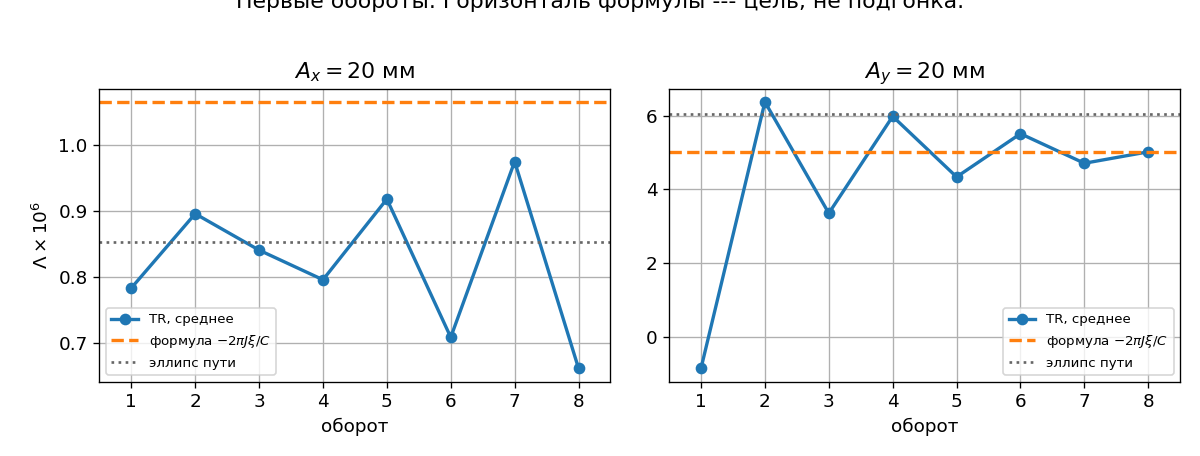

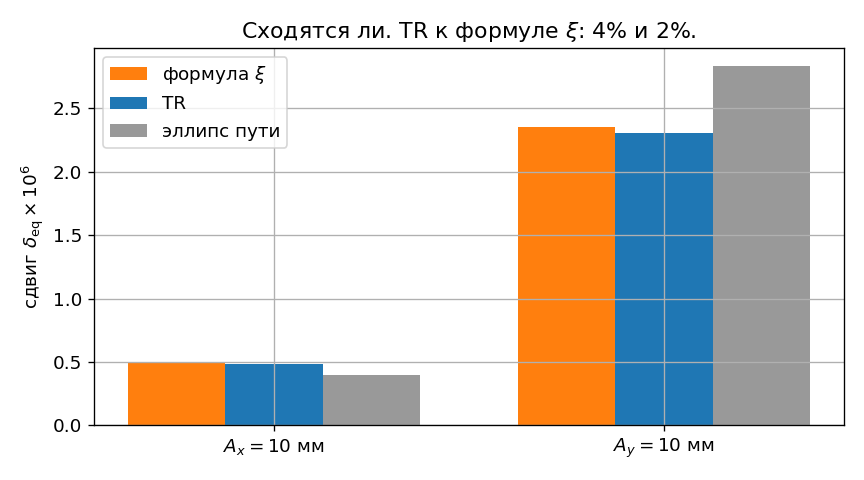

Lambda 20 мм x:  ξ 1.066e-06  TR(8 оборотов) 6.610e-07  путь 8.525e-07
Lambda 20 мм y:  ξ 5.017e-06  TR(8 оборотов) 5.018e-06  путь 6.056e-06
сдвиг 10 мм x:   ξ 4.990e-07  TR 4.814e-07  путь 3.992e-07
сдвиг 10 мм y:   ξ 2.350e-06  TR 2.309e-06  путь 2.836e-06


In [10]:
def lambda_turns(t_amp, t0):
    return -KG * (np.diff(t_amp) - np.diff(t0)) / C

Lx = lambda_turns(R[4]["t"], R[1]["t"])
Ly = lambda_turns(R[5]["t"], R[1]["t"])
lamx_xi = M["LT_xi_x"] * M["Jx20"]
lamy_xi = M["LT_xi_y"] * M["Jy20"]
N8 = 8
n = np.arange(1, N8 + 1)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8), sharex=True)
ax[0].plot(n, runmean(Lx[:N8]) * 1e6, "o-", lw=2, color="C0", label="TR, среднее")
ax[0].axhline(lamx_xi * 1e6, color="C1", ls="--", lw=2, label=r"формула $-2\pi J\xi/C$")
ax[0].axhline(M["Lambda_x_20"] * 1e6, color="0.4", ls=":", lw=1.6, label="эллипс пути")
ax[0].set_title(r"$A_x=20$ мм")
ax[0].set_ylabel(r"$\Lambda\times 10^{6}$")
ax[1].plot(n, runmean(Ly[:N8]) * 1e6, "o-", lw=2, color="C0", label="TR, среднее")
ax[1].axhline(lamy_xi * 1e6, color="C1", ls="--", lw=2, label=r"формула $-2\pi J\xi/C$")
ax[1].axhline(M["Lambda_y_20"] * 1e6, color="0.4", ls=":", lw=1.6, label="эллипс пути")
ax[1].set_title(r"$A_y=20$ мм")
for a in ax:
    a.set_xlabel("оборот")
    a.set_xlim(0.5, 8.5)
    a.legend(fontsize=8)
fig.suptitle("Первые обороты. Горизонталь формулы --- цель, не подгонка.", y=1.02)
fig.tight_layout()
fig.savefig(DAT / "fig_05_path_mean.png")
display(Image(filename=str(DAT / "fig_05_path_mean.png")))
plt.close()

shift_xi = np.array([M["deq_x_xi"] - M["deq0"], M["deq_y_xi"] - M["deq0"]])
shift_path = np.array([M["deq_x"] - M["deq0"], M["deq_y"] - M["deq0"]])
shift_tr = np.array([c2 - c1, c3 - c1])
fig, ax = plt.subplots(figsize=(7.2, 4.0))
x = np.arange(2)
w = 0.25
ax.bar(x - w, shift_xi * 1e6, w, label=r"формула $\xi$", color="C1")
ax.bar(x, shift_tr * 1e6, w, label="TR", color="C0")
ax.bar(x + w, shift_path * 1e6, w, label="эллипс пути", color="0.6")
ax.set_xticks(x, [r"$A_x=10$ мм", r"$A_y=10$ мм"])
ax.set_ylabel(r"сдвиг $\delta_\mathrm{eq}\times 10^{6}$")
ax.set_title(r"Сходятся ли. TR к формуле $\xi$: 4% и 2%.")
ax.legend()
fig.tight_layout()
fig.savefig(DAT / "fig_05_compare.png")
display(Image(filename=str(DAT / "fig_05_compare.png")))
plt.close()
print("Lambda 20 мм x:  ξ %.3e  TR(8 оборотов) %.3e  путь %.3e" % (
    lamx_xi, runmean(Lx[:N8])[-1], M["Lambda_x_20"]))
print("Lambda 20 мм y:  ξ %.3e  TR(8 оборотов) %.3e  путь %.3e" % (
    lamy_xi, runmean(Ly[:N8])[-1], M["Lambda_y_20"]))
print("сдвиг 10 мм x:   ξ %.3e  TR %.3e  путь %.3e" % (shift_xi[0], shift_tr[0], shift_path[0]))
print("сдвиг 10 мм y:   ξ %.3e  TR %.3e  путь %.3e" % (shift_xi[1], shift_tr[1], shift_path[1]))

## 06. Сдвиг $\delta_\mathrm{eq}$ от удлинения

Тот же размах импульса, полость включена. Одна частица без бетатрона, другая с $A_x=10$ мм или $A_y=10$ мм. Сырое скользящее среднее стартует с $\delta_m=10^{-3}$ и на этом масштабе сдвиг не виден. Ниже из каждого ряда вычтена гармоника $Q_s$: остаётся постоянный уровень. Три линии --- без $\Lambda$, с $\Lambda_x$, с $\Lambda_y$.

Сдвиг равен $-\Lambda/\eta_0$. Он пропорционален действию, не амплитуде: 20 мм даёт вчетверо больший сдвиг, чем 10 мм.

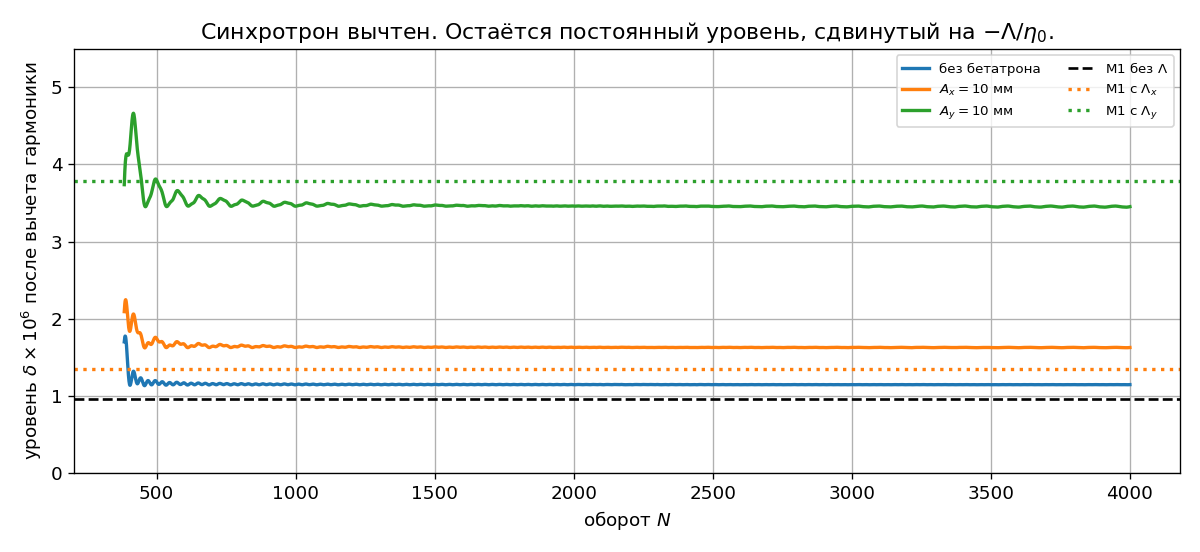

сдвиг 10 мм x:  центр M3 4.814e-07   формула путь 3.992e-07   формула xi 4.990e-07
сдвиг 10 мм y:  центр M3 2.309e-06   формула путь 2.836e-06   формула xi 2.350e-06
сдвиг 20 мм x:  центр M3 1.928e-06   формула путь 1.597e-06
сдвиг 20 мм y:  центр M3 9.162e-06   формула путь 1.134e-05


In [11]:
def detrend_level(delta, Qs):
    n = np.arange(len(delta), dtype=float)
    w = 2.0 * np.pi * Qs
    A = np.column_stack([
        np.ones_like(n), np.cos(w * n), np.sin(w * n),
        np.cos(2 * w * n), np.sin(2 * w * n),
    ])
    coef, *_ = np.linalg.lstsq(A, delta, rcond=None)
    return delta - A[:, 1:] @ coef[1:]

fig, ax = plt.subplots(figsize=(10, 4.6))
for rid, lab, col in [(1, "без бетатрона", "C0"), (2, r"$A_x=10$ мм", "C1"), (3, r"$A_y=10$ мм", "C2")]:
    lvl = detrend_level(R[rid]["delta"], Qs)
    ax.plot(R[rid]["n"][drop:], runmean(lvl[drop:]) * 1e6, lw=2.0, color=col, label=lab)
ax.axhline(M["deq0"] * 1e6, color="k", ls="--", lw=1.6, label=r"M1 без $\Lambda$")
ax.axhline(M["deq_x"] * 1e6, color="C1", ls=":", lw=2.0, label=r"M1 с $\Lambda_x$")
ax.axhline(M["deq_y"] * 1e6, color="C2", ls=":", lw=2.0, label=r"M1 с $\Lambda_y$")
ax.set_xlabel("оборот $N$")
ax.set_ylabel(r"уровень $\delta\times 10^{6}$ после вычета гармоники")
ax.set_title(r"Синхротрон вычтен. Остаётся постоянный уровень, сдвинутый на $-\Lambda/\eta_0$.")
ax.set_ylim(0.0, 5.5)
ax.legend(fontsize=8, ncol=2)
fig.tight_layout()
fig.savefig(DAT / "fig_06_lambda.png")
display(Image(filename=str(DAT / "fig_06_lambda.png")))
plt.close()

print("сдвиг 10 мм x:  центр M3 %.3e   формула путь %.3e   формула xi %.3e" % (
    c2 - c1, M["deq_x"] - M["deq0"], M["deq_x_xi"] - M["deq0"]))
print("сдвиг 10 мм y:  центр M3 %.3e   формула путь %.3e   формула xi %.3e" % (
    c3 - c1, M["deq_y"] - M["deq0"], M["deq_y_xi"] - M["deq0"]))
print("сдвиг 20 мм x:  центр M3 %.3e   формула путь %.3e" % (
    c4 - c1, -M["Lambda_x_20"] / M["eta0"]))
print("сдвиг 20 мм y:  центр M3 %.3e   формула путь %.3e" % (
    c5 - c1, -M["Lambda_y_20"] / M["eta0"]))

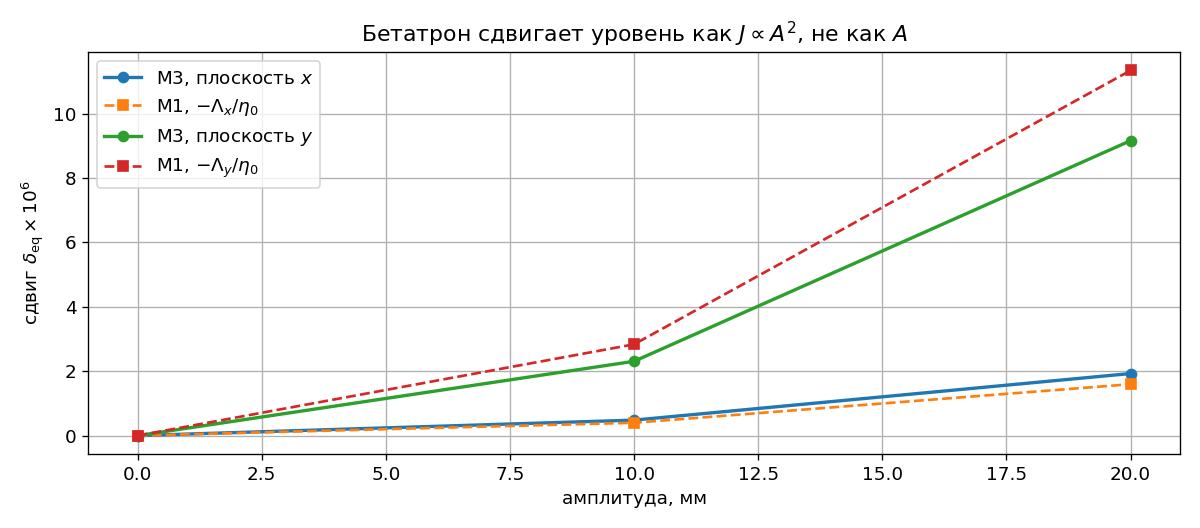

In [12]:
fig, ax = plt.subplots(figsize=(10, 4.4))
Ns = np.array([0.0, 10.0, 20.0])
shift_x_m3 = np.array([0.0, c2 - c1, c4 - c1]) * 1e6
shift_y_m3 = np.array([0.0, c3 - c1, c5 - c1]) * 1e6
shift_x_m1 = np.array([0.0, M["deq_x"] - M["deq0"], -M["Lambda_x_20"] / M["eta0"]]) * 1e6
shift_y_m1 = np.array([0.0, M["deq_y"] - M["deq0"], -M["Lambda_y_20"] / M["eta0"]]) * 1e6
ax.plot(Ns, shift_x_m3, "o-", lw=2, label=r"M3, плоскость $x$")
ax.plot(Ns, shift_x_m1, "s--", lw=1.6, label=r"M1, $-\Lambda_x/\eta_0$")
ax.plot(Ns, shift_y_m3, "o-", lw=2, label=r"M3, плоскость $y$")
ax.plot(Ns, shift_y_m1, "s--", lw=1.6, label=r"M1, $-\Lambda_y/\eta_0$")
ax.set_xlabel(r"амплитуда, мм")
ax.set_ylabel(r"сдвиг $\delta_\mathrm{eq}\times 10^{6}$")
ax.set_title(r"Бетатрон сдвигает уровень как $J\propto A^2$, не как $A$")
ax.legend()
fig.tight_layout()
fig.savefig(DAT / "fig_06_shift.png")
display(Image(filename=str(DAT / "fig_06_shift.png")))
plt.close()

## 07. Две записи одного сдвига

Формула: $\partial\delta_\mathrm{eq}/\partial J_x=2\pi\xi_x/(C\eta_0)$. Карта пути даёт то же через $\Lambda/J$. Нормальная форма знает $Q_s$ без этих имён. Трекинг проверяет сдвиг как разность центров.

In [13]:
dx_xi = M["d_deq_dJx"]
dy_xi = M["d_deq_dJy"]
dx_path = -M["LT_Jx"] / M["eta0"]
dy_path = -M["LT_Jy"] / M["eta0"]
dx_m3 = (c2 - c1) / M["Jx"]
dy_m3 = (c3 - c1) / M["Jy"]
print("%22s %14s %14s %14s" % ("", "из xi", "из пути", "из M3"))
print("%22s %14.5e %14.5e %14.5e" % ("d deq / d Jx", dx_xi, dx_path, dx_m3))
print("%22s %14.5e %14.5e %14.5e" % ("d deq / d Jy", dy_xi, dy_path, dy_m3))
print()
print("M4 SY минус M3, луч 1: %.3e" % (cs1 - c1))
print("M4 SY минус M3, 10 мм x: %.3e" % (cs2 - c2))

                                из xi        из пути          из M3
          d deq / d Jx    1.84563e-01    1.47647e-01    1.78051e-01
          d deq / d Jy    1.85252e-01    2.23614e-01    1.82040e-01

M4 SY минус M3, луч 1: -8.218e-10
M4 SY минус M3, 10 мм x: 5.051e-10


## Что видно

Коэффициенты разложения `MAP` сходятся с Julia: $\eta_0,\eta_1,Q_s$ и $\xi$ из квадратичной части `MAP(5)`. Процедура `TP` --- другое разложение (энергия параметром) и с Julia не сходится: 26% и 17%. Для удлинения и $\delta_\mathrm{eq}$ из карты берём `MAP(5)`, не `TP`.